# **1. Q-Table**
- Q는 "현재 상태에서 이 행동을 했을 때 앞으로 얼마나 유리한가"를 나타내는 행동가치
- Q-Table은 이 값을 표 형태로 저장
- Q-Table은 정답표가 아님. 에이전트가 보상을 경험하며 채우고 수정하는 표

### Q-Table의 한계
- 로봇은 거리, 속도 , 방향 등 연속적인 숫자를 받음
- 상태를 세밀하게 구분하면 조합이 매우 큼. 예) 센서 3개를 각각 100단계로 구분하고 행동이 4개라면 100 * 100 * 100 * 4  = 4000000개의 Q값이 필요
- 상태마다 숫자를 저장한느 대신 상태 -> 신경망 -> 각 행동의 Q값이라는 관계를 학습
    - 처음 보는 상태도 비슷한 학습 경험을 활용해 Q깂을 예측 -> 함수 근사

> 신경망이 언제나 정확한 것은 아님. 학습 경험이 부족하거나 새로운 상황이 너무 다르면 잘못 예측할 수 있음

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

small = np.zeros((5, 2))
large_count = 100 ** 3 * 4
print('작은 미로 Q-Table 크기:', small.shape, '→', small.size, '개')
print('센서 3개를 100단계로 구분할 때:', f'{large_count:,}', '개')
print('float32로 저장할 때 약:', round(large_count * 4 / 1024**2, 2), 'MiB')

작은 미로 Q-Table 크기: (5, 2) → 10 개
센서 3개를 100단계로 구분할 때: 4,000,000 개
float32로 저장할 때 약: 15.26 MiB


In [3]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [4]:
x = torch.arange(1, 6, dtype=torch.float32).unsqueeze(1)
y = x / 6.0
model = nn.Linear(1, 1)
optimizer = optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    prediction = model(x)
    loss = ((prediction - y) ** 2).mean()
    optimizer.zero_grad() # 미분값 초기화
    loss.backward()
    optimizer.step()

In [5]:
print('w, b: ', model.weight.item(), model.bias.item()),
print('상태 2.5의 예측 가치: ', model(torch.tensor([[2.5]])).item())

w, b:  0.16890689730644226 -0.008087950758635998
상태 2.5의 예측 가치:  0.4141792953014374


### DQN이 단순한 신경망 하나가 아닌 이유
- 신경망에 상태를 넣고  Q값만 예측할 수 없음
- 강화학습 데이터는 일반적인 사진 분류 데이터와 다르게 시간 순서대로 서로 비슷한 경험이 연속해서 발생
- 학습 목표를 만드는 데 사용하는 Q값도 신경망이 추정하므로 목표 자체가 계속 바뀜

1. Q-Network: 현재 상태를 보고 각 행동의 Q점수를 예측. 예) [왼쪽=12.1, 오른쪽=15.4]라면 오른쪽이 더 좋다고 판단
2. Experience Replay(경험 재생): 상태, 행동, 보상, 다음 상태, 종료 여부를 메모리에 모아 둠. 학습할 때는 최근 경험 하나만 쓰지 않고 경험을 무작위로 섞어 뽑음. 연속 경험 사이의 상관성을 완화하고 경험을 재사용할 수 있음
3. Target Network(타깃 신경망): 학습하는 네트워크와 별도로 목표값 계산용 네트워크를 둠. 목표값이 매번 너무 급격히 움직이지 않도록 일정 주기마다 학습 네트워크의 가중치를 복사함

> Target Network는 잠시 고정된 정답지 역할.  Replay Buffer는 과거 문제를 섞어 복습하는 문제은행과 비슷

> 타깃 신경망이 실제 정답을 아는 것은 아님. 역시 추정값을 제공할 뿐임


----------------------------------------------------
# 여기서부터 빠진 구간

### 지도학습과 DQN 학습의 차이
1. 위 지도학습 예시
- 입력: 숫자 x
- 목표값: 미리 정한 x/6
- 출력: 예측 숫자 1개
- 학습: 손실 > 역전파 > 가중치 수정

2. DQN
- 입력: 환경에서 관측한 상태
- 목표값: 보상 + 할인된 다음 상태 가치
- 출력: 각 이산 행동의 Q값
- 학습: 손실 > 역전파 > 가중치 수정

> 이산 행동: 에이전트가 선택할 수 있는 행동이 정해진 개수로 구분되어 있는 것

> 연속 행동: 일정한 범위 안에서 연속적인 값을 선택하는 행동. 예) 자동차 핸들 -2.0 ~ 2.0 조절

> Q값: 현재 상태에서 특정 행동을 선택했을 때 앞으로 얻을 것으로 기대되는 누적 보상

### CarPole
- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모름
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓음. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info)를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

In [6]:
import gymnasium as gym

In [7]:
probe = gym.make('CartPole-v1')
obs, info = probe.reset(seed=SEED)
# obs: [위치, 속도, 각도, 각속도]
# observation_space: 유한한 박스 공간을 만들어 obs의 값을 넣기 위함
print('관측: ', obs, ' | 관측 공간: ', probe.observation_space)
print('행동 공간: ', probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print('한 단계 결과: ', reward, terminated, truncated)
probe.close()

관측:  [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간:  Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간:  Discrete(2)
한 단계 결과:  1.0 False False


### Replay Buffer
- 경험 저장소. 예) (상태 4개, 오른쪽, +1, 다음 상태 4개, False)

In [8]:
class ReplayBuffer:
    def __init__(self, capacity=30000):
        self.data = deque(maxlen=capacity)
    def add(self, s, a, r, ns, terminated):
        self.data.append((s, a, r, ns, terminated))
    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        s, a, r, ns, d = zip(*batch)
        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))
    def __len__(self):
        return len(self.data)

In [9]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    def forward(self, x):
        return self.net(x)

In [10]:
q_test = QNetwork().to(DEVICE)
q_test

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [11]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


```
현재 상태에서 오른쪽 행동의 신경망 예측이 Q=4라고 가정
행동 후 보상 +1을 받았고, 타깃 신경망이 다음 상태의 최고 Q를 6이라고 예측했다면,
할인율 0.9에서 목표는 1+0.9*6=6.4

현재 예측 4와 목표 6.4사이의 차이가 있으므로, 신경망 가중치를 조금 수정해 오른쪽 행동의 Q예측이 목표에 가까워지게 함
```

In [12]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)
    # gather: 신경망이 출력한 여러 행동 점수 중 실제로 선택했던 행동의 점수만 추출
    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만듦
    chosen_q = online(states).gather(1, actions)
    with torch.no_grad():
        if double:
            # 행동을 고른 다음 그 행동을 평가
            next_actions = online(next_states).argmax(dim=1, keepdim=True)
            next_q = target(next_states).gather(1, next_actions)

        else:
            # 다음 상태의 최대 q값 구함
            next_q = target(next_states).max(dim=1, keepdim=True).values
            # TD 목표값
        targets = rewards + gamma * (1-terminated) * next_q
    loss = nn.functional.smooth_l1_loss(chosen_q, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return float(loss.item())

- DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() tlfgod
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에피소드의 이동평균 보상

------------------------------------------
# 빠진 구간

In [14]:
def train_cartpole(episodes=250, double=False, seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    online = QNetwork().to(DEVICE)
    target = QNetwork().to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = optim.Adam(online.parameters(), lr=5e-4)
    replay = ReplayBuffer()
    returns = []
    losses = []
    steps = 0
    for episode in range(episodes):
        state, _ = env.reset(seed=seed+episode)
        total = 0.0
        for t in range(500):
            # 초반에는 무작위 행동을 많이 하고, 이후 점차 학습된 행동을 활용
            epsilon = max(0.05, 1.0-steps/12000)
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = int(online(tensor).argmax(dim=1).item())
            next_state, reward, terminated, truncated, _ = env.step(action)
            replay.add(state, action, reward, next_state, terminated)
            state = next_state
            total += reward
            steps += 1
            # 경험이 1000개 이상 쌓인 후 4스텝마다 dqn_update()로 신경망을 학습
            if len(replay) >= 1000 and steps % 4 == 0:
                losses.append(dqn_update(online, target, replay, optimizer, double=double))
            # 500스텝마다 online의 가중치를 target에 복사. 역전파가 아닌 가중치 동기화
            if steps % 500 == 0:
                target.load_state_dict(online.state_dict())
            if terminated or truncated: break
        returns.append(total)
        if (episode+1) % 50 == 0:
            print(f'{episode+1:3d}회 | 최근 20회 평균 보상: {np.mean(returns[-20:]):.1f}')
    env.close()
    return online, returns, losses

In [17]:
trained_q, train_returns, train_losses = train_cartpole(episodes=250)

 50회 | 최근 20회 평균 보상: 26.6
100회 | 최근 20회 평균 보상: 22.5
150회 | 최근 20회 평균 보상: 31.5
200회 | 최근 20회 평균 보상: 93.0
250회 | 최근 20회 평균 보상: 200.6


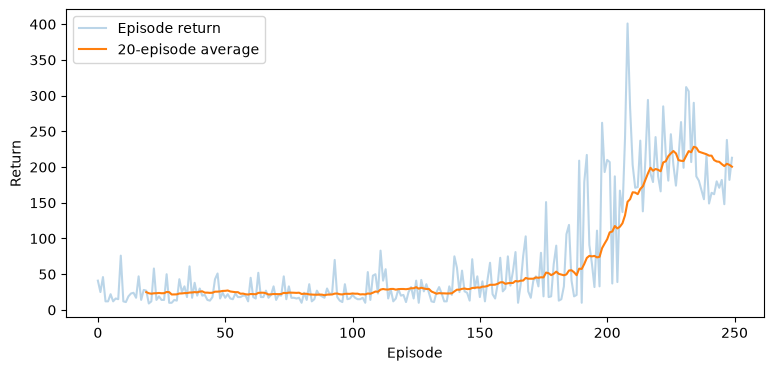

In [ ]:
# 학습이 불안정하면 에피소드 수, 탐험률, 학습률 등 확인
plt.figure(figsize=(9,4))
plt.plot(train_returns,alpha=.3,label='Episode return')
if len(train_returns)>=20:
    plt.plot(np.arange(19,len(train_returns)),np.convolve(train_returns,np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()